<a href="https://colab.research.google.com/github/Sushant2007-srm/ML-Lab/blob/main/Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving drug200.csv to drug200 (7).csv
First 5 Rows:


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY



Dataset Shape: (200, 6)

Missing Values:
 Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64


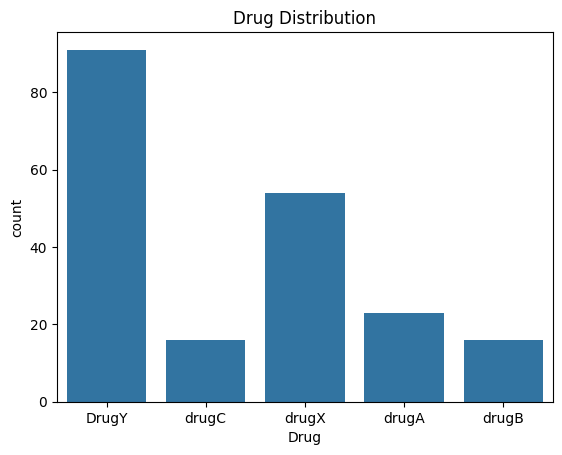

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Upload Dataset
uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0])

# Display Dataset
print("First 5 Rows:")
display(df.head())

print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

# Visualize Drug Distribution
sns.countplot(data=df, x='Drug')
plt.title("Drug Distribution")
plt.show()

In [ ]:
# DATA PREPROCESSING
X = df.drop('Drug', axis=1)

X = pd.get_dummies(X, columns=['Sex', 'BP', 'Cholesterol'])

# ---------------- CLASSIFICATION ----------------

y_class = df['Drug']

X_train, X_test, y_train, y_test = train_test_split(
    X, y_class, test_size=0.2,
    random_state=42, stratify=y_class
)

# Random Forest Classifier
classifier = RandomForestClassifier(
    n_estimators=100, random_state=42
)

classifier.fit(X_train, y_train)

class_pred = classifier.predict(X_test)

print("CLASSIFICATION COMPLETED!")

# ---------------- REGRESSION ----------------

# Predict Na_to_K using other features
X_reg = X.drop(columns=['Na_to_K'])
y_reg = df['Na_to_K']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Random Forest Regressor
regressor = RandomForestRegressor(
    n_estimators=100, random_state=42
)

regressor.fit(X_train_reg, y_train_reg)

reg_pred = regressor.predict(X_test_reg)

print("REGRESSION COMPLETED!")

CLASSIFICATION COMPLETED!
REGRESSION COMPLETED!


===== RANDOM FOREST CLASSIFICATION =====
Accuracy: 97.5 %

Classification Report:
              precision    recall  f1-score   support

       DrugY       0.95      1.00      0.97        18
       drugA       1.00      1.00      1.00         5
       drugB       1.00      1.00      1.00         3
       drugC       1.00      1.00      1.00         3
       drugX       1.00      0.91      0.95        11

    accuracy                           0.97        40
   macro avg       0.99      0.98      0.99        40
weighted avg       0.98      0.97      0.97        40



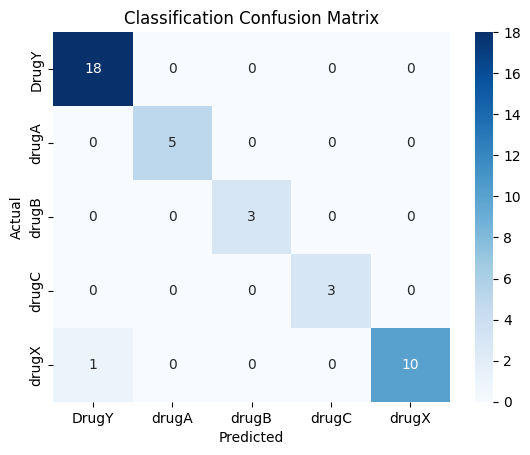


===== RANDOM FOREST REGRESSION =====
Mean Absolute Error: 7.03054325972222
Mean Squared Error: 73.53990579755151
Root Mean Squared Error: 8.57554113730157
R2 Score: -0.4657408410307269


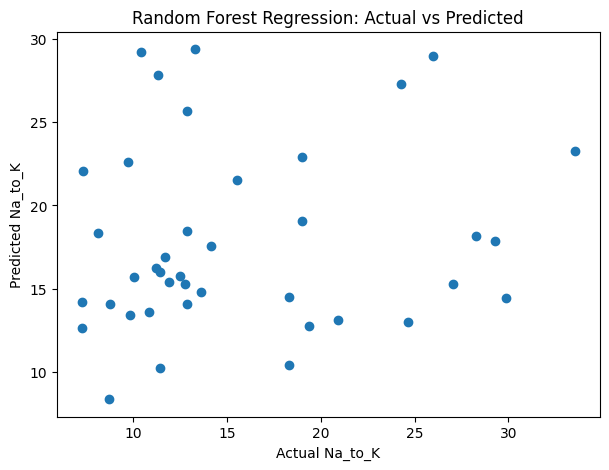

In [ ]:
# CLASSIFICATION EVALUATION

print("===== RANDOM FOREST CLASSIFICATION =====")

accuracy = accuracy_score(y_test, class_pred)

print("Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, class_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, class_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classifier.classes_,
            yticklabels=classifier.classes_)

plt.title("Classification Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# REGRESSION EVALUATION

print("\n===== RANDOM FOREST REGRESSION =====")

print("Mean Absolute Error:", mean_absolute_error(y_test_reg, reg_pred))

print("Mean Squared Error:", mean_squared_error(y_test_reg, reg_pred))

rmse = np.sqrt(mean_squared_error(y_test_reg, reg_pred))
print("Root Mean Squared Error:", rmse)

print("R2 Score:", r2_score(y_test_reg, reg_pred))


# Actual vs Predicted Values
plt.figure(figsize=(7,5))

plt.scatter(y_test_reg, reg_pred)

plt.xlabel("Actual Na_to_K")
plt.ylabel("Predicted Na_to_K")

plt.title("Random Forest Regression: Actual vs Predicted")

plt.show()